# DTBench: LLM-based generation and validation of decision-table test cases

Runnable walkthrough of the experiment. It uses the model responses saved in `results/raw`, so no LLM is
needed. Run all cells from top to bottom (about one minute).

1. Benchmark: specifications, ground-truth tables, verification
2. One specification end to end (S07 vacation days)
3. Ground-truth-free validation and repair of a model's table
4. Full results, statistics and figures
5. Mutation analysis example

In [1]:
import json, pathlib, sys, inspect
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "dtbench").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from dtbench.specs import SPECS, SPEC_BY_ID
from dtbench.table import DecisionTable
from dtbench.probes import gt_probes
from dtbench.validator import structural_check, issues_text, gt_table_eval
from dtbench.derive import derive_tests
from dtbench.test_eval import assess_tests
from dtbench import mutation
pd.set_option("display.max_colwidth", 120)
print("repository folder:", ROOT.name, "| specifications:", len(SPECS))

repository folder: dtbench | specifications: 12


## 1. Benchmark

In [2]:
pd.DataFrame([{"id": s.id, "name": s.name, "category": s.category, "inputs": len(s.inputs),
               "gt_conditions": len(s.gt_table["conditions"]), "gt_rules": len(s.feasible_gt_rules()),
               "tags": ", ".join(s.tags)} for s in SPECS])

,id,name,category,inputs,gt_conditions,gt_rules,tags
0,S01,Triangle classification,Textbook,3,6,8,"relational conditions, impossible combinations"
1,S02,NextDate,Textbook,3,8,22,"many rules, leap-year logic, invalid dates"
2,S03,Order discount,Business rules (authored),3,6,17,"tiers, cap, error rule"
3,S04,BMI level,GPT-DMN,3,4,7,"computed quantity, decimal boundaries"
4,S05,Pet adoption,GPT-DMN,4,5,8,"enumerations, default rule, ambiguous wording"
5,S06,Driver's licence,GPT-DMN,6,6,7,"many inputs, conjunction"
6,S07,Vacation days,GPT-DMN,2,5,6,"overlapping clauses, exception, input constraint"
7,S08,Mode of transportation,GPT-DMN,3,7,12,"distance bands, enumerations, clarified boundaries"
8,S09,Scholarship eligibility,GPT-DMN,3,3,4,"conjunction, small"
9,S10,Login with lockout and OTP,Business rules (authored),5,5,6,"security, precedence, threshold"


In [3]:
# Every ground-truth table must agree with its independent reference implementation on every probe
rows = []
for s in SPECS:
    gt = DecisionTable(s.gt_table, s)
    probes = gt_probes(s)
    mismatches = sum(1 for p in probes if gt.decide(p)[1] != s.reference_output(p))
    rows.append({"spec": s.id, "probes": len(probes), "mismatches": mismatches})
check = pd.DataFrame(rows)
print("total probes:", check.probes.sum(), "| total mismatches:", check.mismatches.sum())
check

total probes: 77818 | total mismatches: 0


,spec,probes,mismatches
0,S01,35582,0
1,S02,8174,0
2,S03,4003,0
3,S04,5241,0
4,S05,24,0
5,S06,4616,0
6,S07,1540,0
7,S08,3953,0
8,S09,4073,0
9,S10,160,0


## 2. One specification end to end: S07 vacation days

In [4]:
spec = SPEC_BY_ID["S07"]
print(spec.rules_text, "\n")
print(spec.describe_inputs())
print(spec.describe_output())

Every employee receives at least 22 days. Additional days are provided according to the following criteria: Only employees younger than 18 or at least 60 years, or employees with at least 30 years of service will receive 5 extra days. Employees with at least 30 years of service and also employees of age 60 or more, receive 3 extra days, on top of possible additional days already given. If an employee has at least 15 but less than 30 years of service, 2 extra days are given. These 2 days are also provided for employees of age 45 or more. These 2 extra days can not be combined with the extra 5 days. 

- age: integer from 16 to 70
- years_of_service: integer from 0 to 54
Constraint on valid inputs: years_of_service <= age - 16 (nobody starts working before 16)
- vacation_days: an integer


In [5]:
def show_table(table):
    m = table.matrix()
    cols = ["id", "condition"] + [r.id for r in table.rules]
    return pd.DataFrame(m, columns=cols)

gt = DecisionTable(spec.gt_table, spec)
show_table(gt)

,id,condition,R1,R2,R3,R4,R5,R6
0,C1,age < 18,T,F,F,F,F,F
1,C2,age >= 60,-,T,F,F,F,F
2,C3,years_of_service >= 30,-,-,T,F,F,F
3,C4,age >= 45,-,-,-,T,F,F
4,C5,years_of_service >= 15,-,-,-,-,T,F
5,,output,27,30,30,24,24,22


In [6]:
print(inspect.getsource(spec.reference_fn()))

def decide(age, years_of_service):
    days = 22
    extra_five = age < 18 or age >= 60 or years_of_service >= 30
    if extra_five:
        days = days + 5
    if years_of_service >= 30 or age >= 60:
        days = days + 3
    if not extra_five and (15 <= years_of_service < 30 or age >= 45):
        days = days + 2
    return days



## 3. Ground-truth-free validation and repair of a model's table

In [7]:
MODEL = "qwen3-4b"
raw = ROOT / "results" / "raw" / MODEL / spec.id
p1 = json.loads((raw / "P1_table.json").read_text())
print("prompt sent to the model:\n")
print(p1["messages"][1]["content"])

prompt sent to the model:

BUSINESS RULES
Every employee receives at least 22 days. Additional days are provided according to the following criteria: Only employees younger than 18 or at least 60 years, or employees with at least 30 years of service will receive 5 extra days. Employees with at least 30 years of service and also employees of age 60 or more, receive 3 extra days, on top of possible additional days already given. If an employee has at least 15 but less than 30 years of service, 2 extra days are given. These 2 days are also provided for employees of age 45 or more. These 2 extra days can not be combined with the extra 5 days.

INPUTS
- age: integer from 16 to 70
- years_of_service: integer from 0 to 54
Constraint on valid inputs: years_of_service <= age - 16 (nobody starts working before 16)

OUTPUT
- vacation_days: an integer

TASK
Build a decision table for these business rules.
Return JSON with:
- "conditions": a list of {"id": "C1", "expr": "<condition>"}. Each conditi

In [8]:
t1 = DecisionTable(p1["parsed"], spec)
show_table(t1)

,id,condition,R1,R2,R3,R4,R5,R6
0,C1,age < 18 or age >= 60,T,T,F,F,F,F
1,C2,years_of_service >= 30,T,F,T,F,F,F
2,C3,years_of_service >= 15 and years_of_service < 30,F,F,F,T,T,F
3,C4,age >= 45,F,F,F,T,F,F
4,,output,30,27,25,24,24,22


In [9]:
check = structural_check(t1, spec)
print("probes:", check["n_probes"], "| condition combinations:", check["n_combinations"],
      "| missing combinations:", check["gap_combinations"], "| conflicts:", check["conflict_combinations"])
for line in issues_text(t1, spec, check):
    print("-", line)

probes: 618 | condition combinations: 9 | missing combinations: 5 | conflicts: 0
- Missing combination: no rule matches the input age=45, years_of_service=0 (C1=false, C2=false, C3=false, C4=true).
- Missing combination: no rule matches the input age=46, years_of_service=30 (C1=false, C2=true, C3=false, C4=true).
- Missing combination: no rule matches the input age=60, years_of_service=0 (C1=true, C2=false, C3=false, C4=true).
- In total, 5 reachable combinations of your conditions match no rule and 0 match rules with different outputs.


In [10]:
summary = json.loads((raw / "P2_summary.json").read_text())
print("repair rounds:", sum(1 for i in (1, 2) if (raw / f"P2_repair{i}.json").exists()),
      "| table changed:", summary["changed"])
t2 = DecisionTable(summary["final_table"], spec)
c2 = structural_check(t2, spec)
print("after repair -> missing combinations:", c2["gap_combinations"], "| conflicts:", c2["conflict_combinations"])
show_table(t2)

repair rounds: 2 | table changed: True
after repair -> missing combinations: 1 | conflicts: 0


,id,condition,R1,R2,R3,R4,R5,R6,R7,R8,R9,R10,R11
0,C1,age < 18 or age >= 60,T,T,F,F,F,F,F,T,F,T,T
1,C2,years_of_service >= 30,T,F,T,F,F,F,F,F,T,F,T
2,C3,years_of_service >= 15 and years_of_service < 30,F,T,F,T,T,F,F,F,F,T,F
3,C4,age >= 45,F,F,F,T,F,F,T,T,T,T,T
4,,output,30,27,25,24,24,22,24,27,28,27,30


In [11]:
probes = gt_probes(spec)
mutants = mutation.mark_equivalents(spec, mutation.generate(spec), probes)
res = []
for name, table in (("P1 table", t1), ("P2 table", t2), ("ground truth", gt)):
    tests = derive_tests(table, spec)
    m = assess_tests(tests, spec, gt, mutants)
    e = gt_table_eval(table, spec, probes, gt)
    res.append({"table": name, "rules": len(table.rules), "table accuracy": round(e["probe_accuracy"], 3),
                "tests": m["n_tests"], "oracle accuracy": round(m["oracle_accuracy"], 3),
                "rule coverage": round(m["rule_coverage"], 3), "missed rules": ", ".join(m["missed_rules"]),
                "mutation score": round(m["mutation_score"], 3)})
pd.DataFrame(res)

,table,rules,table accuracy,tests,oracle accuracy,rule coverage,missed rules,mutation score
0,P1 table,6,0.429,4,1.000,0.667,"R2, R3",0.542
1,P2 table,11,0.716,8,0.625,0.667,"R1, R3",0.583
2,ground truth,6,1.000,6,1.000,1.000,,0.708


## 4. Full results

In [12]:
import runpy
_ = runpy.run_path(str(ROOT / "scripts" / "make_results.py"), run_name="__main__")

models: ['qwen3-4b', 'llama3.2-3b', 'gemma3-4b']
qwen3-4b     P0  specs=12 tests= 215 oracle=69.6 RC=58.6 missed= 46 MS=72.8
qwen3-4b     P1  specs=12 tests=  68 oracle=87.6 RC=46.8 missed= 59 MS=56.5 tbl_acc=59.2 clean=1
qwen3-4b     P2  specs=12 tests= 108 oracle=80.3 RC=52.3 missed= 53 MS=62.3 tbl_acc=72.9 clean=4
qwen3-4b     P3  specs=12 tests= 241 oracle=100.0 RC=81.1 missed= 21 MS=76.2 tbl_acc=99.9 clean=12
llama3.2-3b  P0  specs=12 tests= 367 oracle=62.1 RC=44.1 missed= 62 MS=63.9
llama3.2-3b  P1  specs=12 tests=  26 oracle=41.7 RC=9.9 missed=100 MS=13.0 tbl_acc=12.3 clean=1
llama3.2-3b  P2  specs=12 tests=  95 oracle=43.2 RC=13.5 missed= 96 MS=17.0 tbl_acc=15.6 clean=1
llama3.2-3b  P3  specs=12 tests= 167 oracle=91.4 RC=56.8 missed= 48 MS=61.1 tbl_acc=80.4 clean=11
gemma3-4b    P0  specs=12 tests= 301 oracle=61.2 RC=57.7 missed= 47 MS=69.1
gemma3-4b    P1  specs=12 tests=  65 oracle=60.7 RC=29.7 missed= 78 MS=30.6 tbl_acc=39.4 clean=0
gemma3-4b    P2  specs=12 tests=  79 oracl

In [13]:
summary = pd.read_csv(ROOT / "results" / "summary.csv")
cols = ["model", "strategy", "tests_total", "validity", "oracle_accuracy", "rule_coverage_pooled",
        "missed_total", "mutation_score_pooled", "tables_clean", "table_accuracy"]
summary[[c for c in cols if c in summary.columns]].round(3)

,model,strategy,tests_total,validity,oracle_accuracy,rule_coverage_pooled,missed_total,mutation_score_pooled,tables_clean,table_accuracy
0,qwen3-4b,P0,215,0.964,0.696,0.586,46,0.728,NaN,NaN
1,qwen3-4b,P1,68,1.000,0.876,0.468,59,0.565,1.0,0.592
2,qwen3-4b,P2,108,1.000,0.803,0.523,53,0.623,4.0,0.729
3,qwen3-4b,P3,241,1.000,1.000,0.811,21,0.762,12.0,0.999
4,llama3.2-3b,P0,367,0.975,0.621,0.441,62,0.639,NaN,NaN
5,llama3.2-3b,P1,26,1.000,0.417,0.099,100,0.130,1.0,0.123
6,llama3.2-3b,P2,95,1.000,0.432,0.135,96,0.170,1.0,0.156
7,llama3.2-3b,P3,167,1.000,0.914,0.568,48,0.611,11.0,0.804
8,gemma3-4b,P0,301,0.965,0.612,0.577,47,0.691,NaN,NaN
9,gemma3-4b,P1,65,1.000,0.607,0.297,78,0.306,0.0,0.394


In [14]:
pd.DataFrame(json.loads((ROOT / "results" / "stats.json").read_text())).round(4)

,metric,comparison,n,better,worse,ties,mean_diff,median_diff,W,p,rank_biserial
0,rule_coverage,P1 vs P0,36,3,24,9,-0.2258,-0.2019,13.0,0.0000,-0.9312
1,rule_coverage,P2 vs P1,36,12,4,20,0.0298,0.0000,38.0,0.1207,0.4412
2,rule_coverage,P2 vs P0,36,5,22,9,-0.1960,-0.1548,51.5,0.0009,-0.7275
3,rule_coverage,P3 vs P2,36,31,0,5,0.4202,0.3542,0.0,0.0000,1.0000
4,rule_coverage,P3 vs P0,36,25,3,8,0.2242,0.1667,24.5,0.0000,0.8793
5,mutation_score,P1 vs P0,36,4,28,4,-0.3140,-0.2826,17.0,0.0000,-0.9356
6,mutation_score,P2 vs P1,36,9,5,22,0.0321,0.0000,28.0,0.1240,0.4667
7,mutation_score,P2 vs P0,36,6,28,2,-0.2819,-0.2684,39.0,0.0000,-0.8689
8,mutation_score,P3 vs P2,36,29,0,7,0.2723,0.2144,0.0,0.0000,1.0000
9,mutation_score,P3 vs P0,36,16,19,1,-0.0097,-0.0381,284.0,0.6115,-0.0984


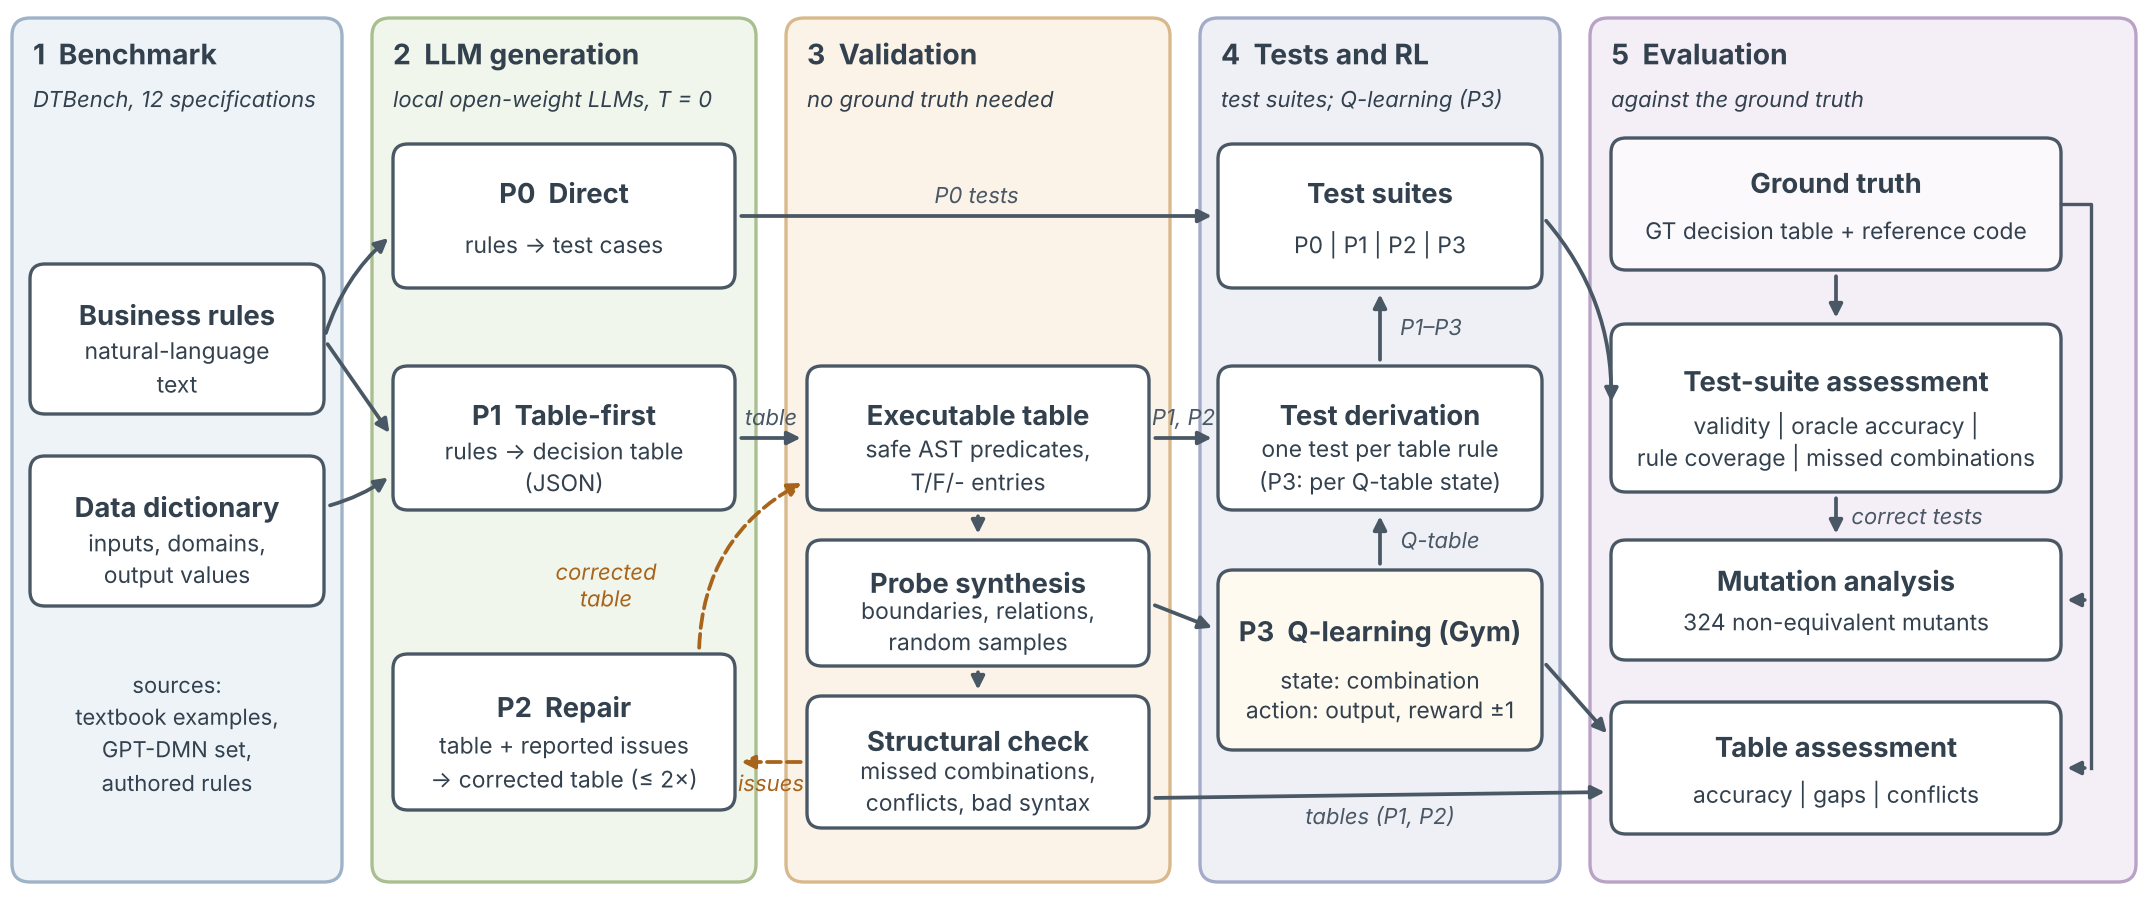

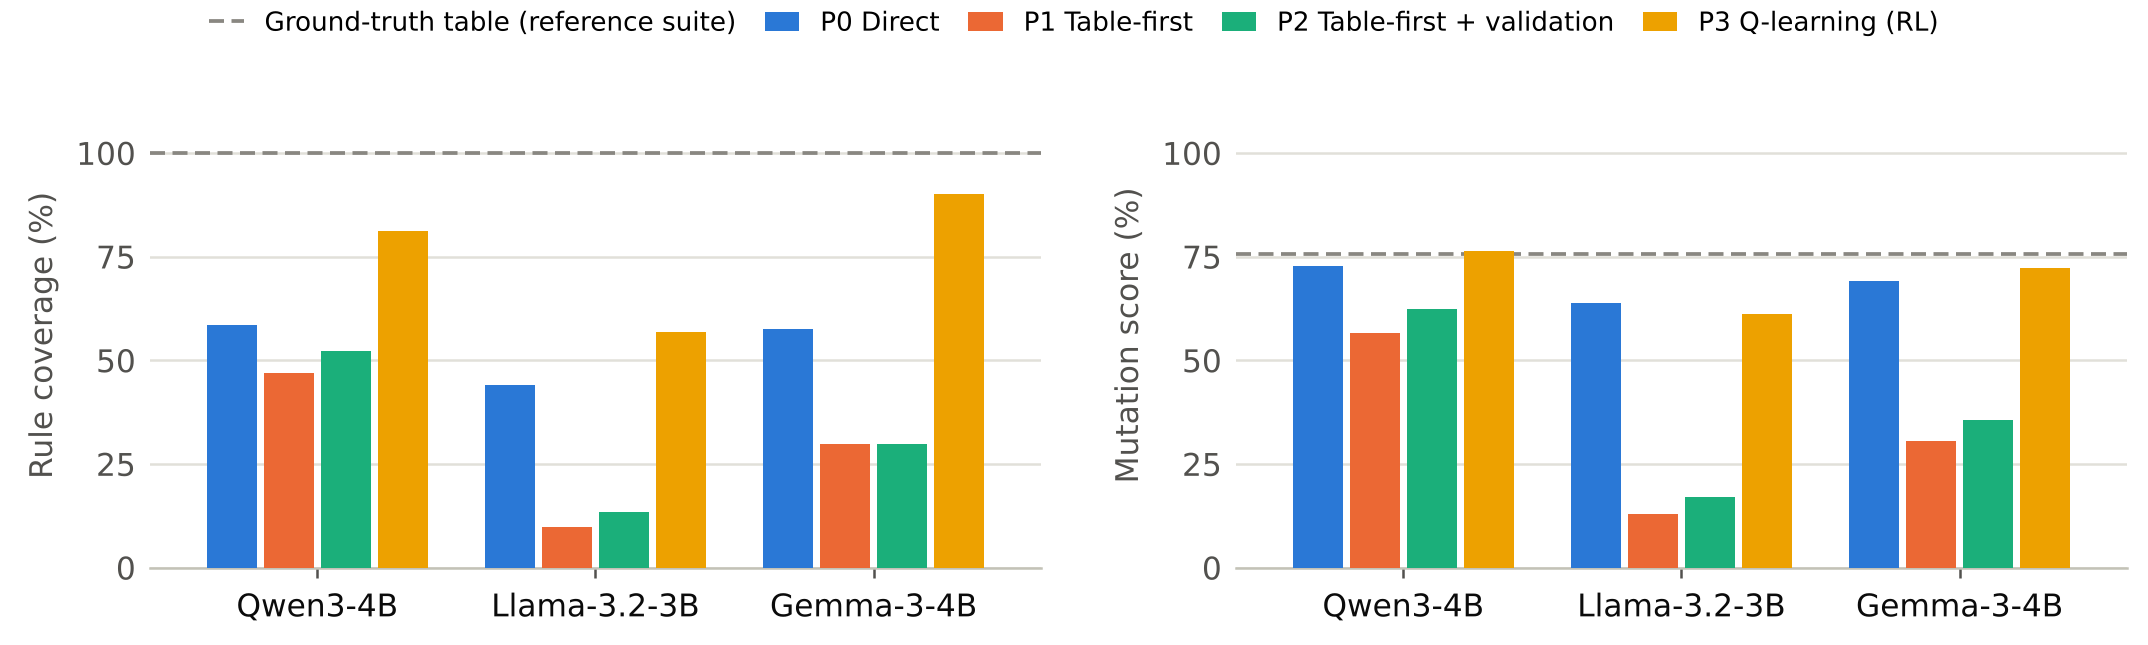

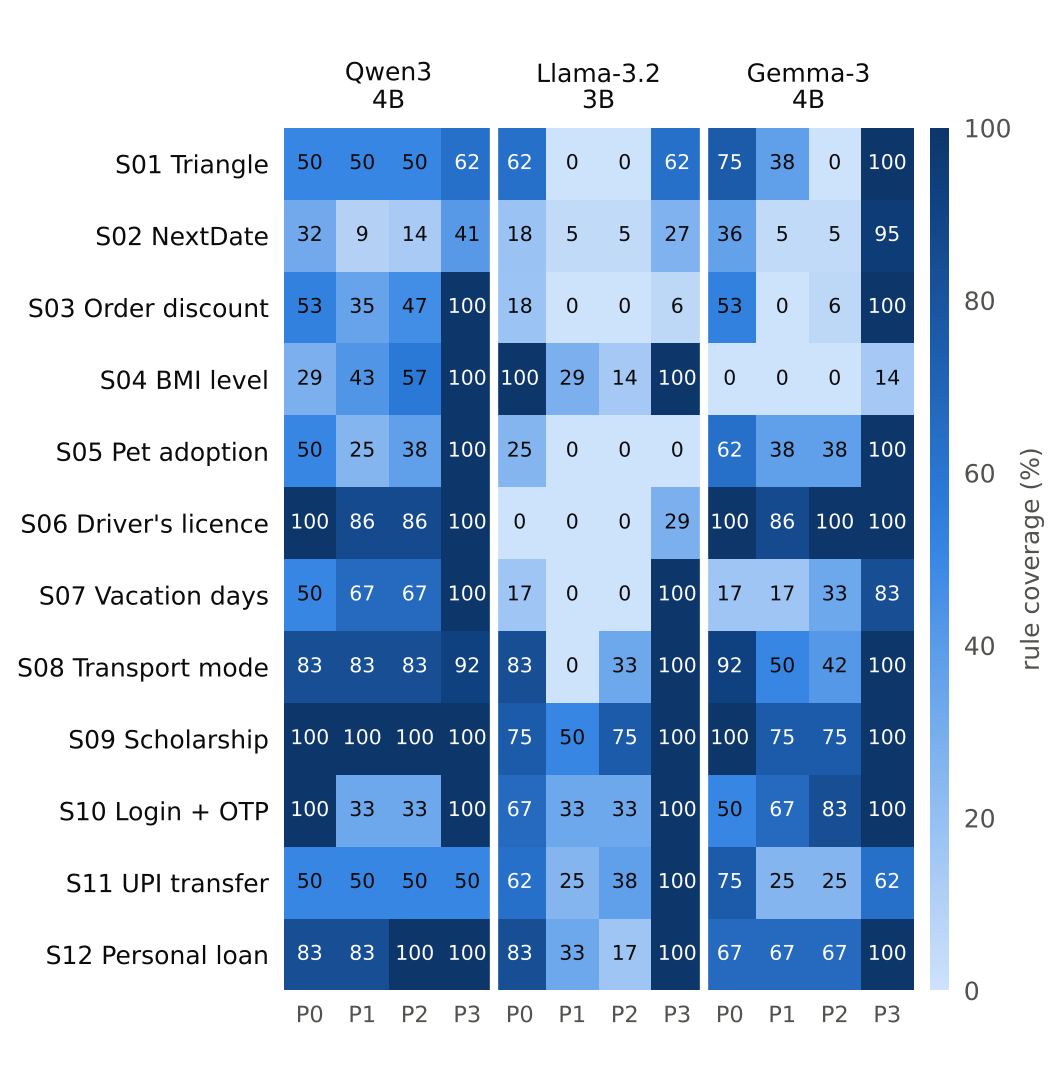

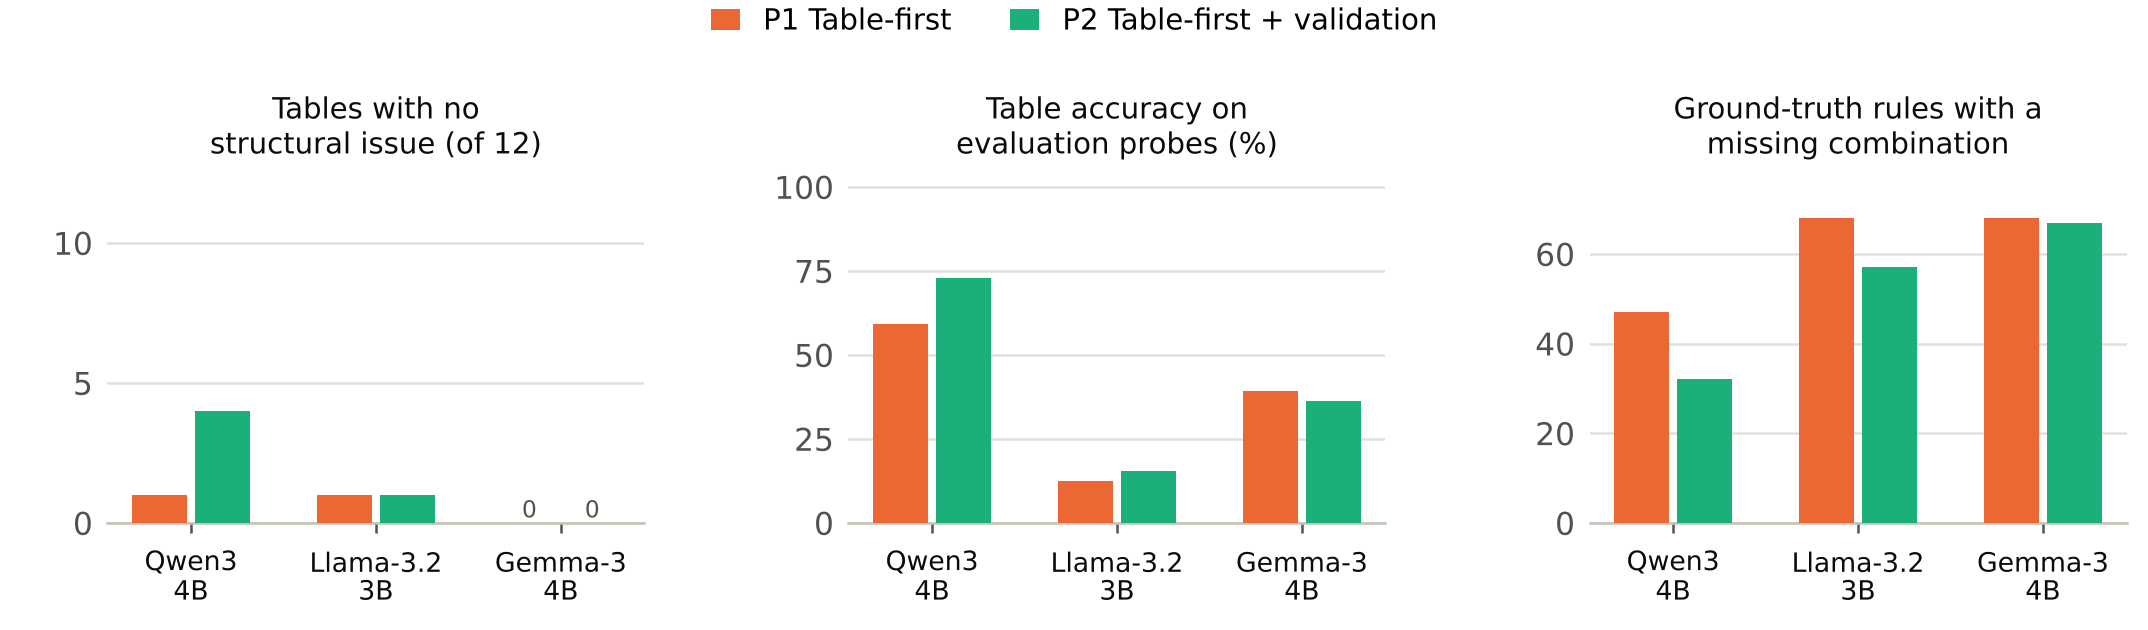

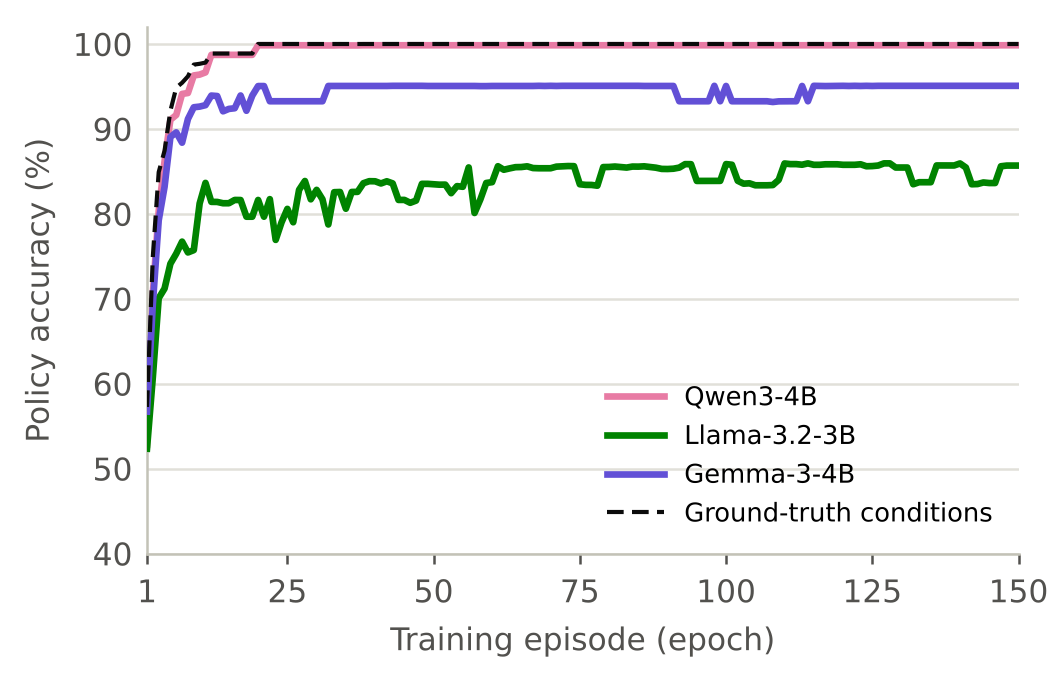

In [15]:
for f in ("architecture.png", "fig_coverage_mutation.png", "fig_heatmap_rule_coverage.png", "fig_validation_repair.png",
          "fig_rl_learning.png"):
    display(Image(filename=str(ROOT / "figures" / f), width=900))

## 5. Mutation analysis example (S11 UPI transfer screening)

In [16]:
s11 = SPEC_BY_ID["S11"]
p11 = gt_probes(s11)
m11 = mutation.mark_equivalents(s11, mutation.generate(s11), p11)
gt11 = DecisionTable(s11.gt_table, s11)
ref_tests = [(t["inputs"], s11.reference_output(t["inputs"])) for t in derive_tests(gt11, s11)]
killed = mutation.kills(s11, m11, ref_tests)
pd.DataFrame([{"mutant": m.id, "operator": m.op, "change": m.desc, "equivalent": m.equivalent,
               "killed by reference suite": m.id in killed} for m in m11])

,mutant,operator,change,equivalent,killed by reference suite
0,S11-M01,NEG,line 5: if-condition negated,False,True
1,S11-M02,NEG,line 7: if-condition negated,False,True
2,S11-M03,NEG,line 9: if-condition negated,False,True
3,S11-M04,ROR,line 5: '>' -> '>=',False,False
4,S11-M05,ROR,line 5: '>' -> '<=',False,True
5,S11-M06,LCR,line 7: 'and' -> 'or',False,True
6,S11-M07,LCR,line 9: 'and' -> 'or',False,True
7,S11-M08,RVR,"line 11: return ""Allowed"" -> ""Blocked""",False,True
8,S11-M09,CRP,line 5: constant 100000 -> 100001,False,False
9,S11-M10,CRP,line 5: constant 100000 -> 99999,False,False


## 6. Q-learning decision table (strategy P3)

A Gymnasium environment shows one test input per step: the **state** is the combination of the LLM's conditions
the input falls in, the **action** is an output value, and the **reward** is +1 if the system under test (the
reference implementation) gives the same output, otherwise -1. One episode visits every combination once
(one epoch). The settings come from `config/rl_config.json`.

In [17]:
import gymnasium as gym
from gymnasium.utils.env_checker import check_env
import dtbench.rl as rl
from dtbench.rl.run import conditions_for, load_config
from dtbench.rl.env import combination_text

cfg = load_config()
print("config/rl_config.json:", cfg)
conds = conditions_for("qwen3-4b", SPEC_BY_ID["S11"], ROOT / "results" / "raw")
print("conditions from Qwen3-4B's P2 table:", [c["expr"] for c in conds])
env = gym.make("dtbench/DecisionTable-v0", spec_id="S11", conditions=conds)
check_env(env.unwrapped)
print("Gymnasium environment checker: passed")
u = env.unwrapped
print("states:", u.observation_space.n, "| actions:", u.actions, "| training inputs:", int(u.counts.sum()))

config/rl_config.json: {'episodes': 150, 'alpha': 0.1, 'gamma': 0.0, 'epsilon_start': 1.0, 'epsilon_min': 0.05, 'epsilon_decay': 0.97, 'reward_correct': 1.0, 'reward_wrong': -1.0, 'seed': 42, 'condition_source': 'P2', 'pool': {'seed': 7, 'max_product': 3000, 'n_relation': 50, 'n_random': 2000}}
conditions from Qwen3-4B's P2 table: ['amount > 100000', 'new_payee == true and amount > 5000', 'registered_device == false and amount > 2000']
Gymnasium environment checker: passed
states: 8 | actions: ['Blocked', 'On hold', 'OTP required', 'Allowed'] | training inputs: 2056


In [18]:
agent = rl.QLearningAgent(u.observation_space.n, u.action_space.n, cfg["alpha"], cfg["gamma"], cfg["seed"])
curve = rl.train(u, agent, cfg["episodes"], cfg["epsilon_start"], cfg["epsilon_min"], cfg["epsilon_decay"], cfg["seed"])
pd.DataFrame(curve).iloc[[0, 4, 9, 19, 49, 99, 149]]

,episode,epsilon,steps,mean_reward,train_accuracy,policy_accuracy
0,1,1.0000,8,-0.75,0.125,0.6070
4,5,0.8853,8,-0.50,0.250,0.8808
9,10,0.7602,8,-0.25,0.375,0.8808
19,20,0.5606,8,0.00,0.500,1.0000
49,50,0.2248,8,1.00,1.000,1.0000
99,100,0.0500,8,1.00,1.000,1.0000
149,150,0.0500,8,1.00,1.000,1.0000


In [19]:
# the learned Q-table: one row per condition combination, one column per output, and the decision
qt = pd.DataFrame(agent.q.round(3), columns=[f"Q[{a}]" for a in u.actions])
qt.insert(0, "combination (" + ", ".join(u.condition_ids) + ")", [combination_text(v) for v in u.states])
qt["decision"] = [u.actions[a] for a in agent.greedy()]
qt

,"combination (C1, C2, C3)",Q[Blocked],Q[On hold],Q[OTP required],Q[Allowed],decision
0,FFF,-0.613,-0.570,-0.522,1.000,Allowed
1,FFT,-0.469,-0.613,1.000,-0.794,OTP required
2,FTT,-0.651,1.000,-0.651,-0.469,On hold
3,FTF,-0.522,1.000,-0.613,-0.686,On hold
4,TFT,1.000,-0.771,-0.570,-0.469,Blocked
5,TFF,1.000,-0.718,-0.651,-0.522,Blocked
6,TTT,1.000,-0.344,-0.651,-0.344,Blocked
7,TTF,1.000,-0.613,-0.651,-0.686,Blocked


In [20]:
# the Q-table as a decision table, its tests, and its metrics against the ground truth
learned = rl.learned_table(u, agent)
ctx = __import__("dtbench.analysis", fromlist=["SpecContext"]).SpecContext(SPEC_BY_ID["S11"])
dt = DecisionTable(learned, SPEC_BY_ID["S11"])
tests = derive_tests(dt, SPEC_BY_ID["S11"])
m = assess_tests(tests, SPEC_BY_ID["S11"], ctx.gt, ctx.mutants)
e = gt_table_eval(dt, SPEC_BY_ID["S11"], ctx.probes, ctx.gt)
print(f"table accuracy {e['probe_accuracy']:.3f}, gaps {e['probe_gap_rate']:.3f}, conflicts {e['probe_conflict_rate']:.3f}")
print(f"tests {m['n_tests']}, rule coverage {m['rule_coverage']:.3f}, mutation score {m['mutation_score']:.3f}")
show_table(dt)

table accuracy 1.000, gaps 0.000, conflicts 0.000
tests 8, rule coverage 0.500, mutation score 0.545


,id,condition,R1,R2,R3,R4,R5,R6,R7,R8
0,C1,amount > 100000,F,F,F,F,T,T,T,T
1,C2,new_payee == True and amount > 5000,F,F,T,T,F,F,T,T
2,C3,registered_device == False and amount > 2000,F,T,T,F,T,F,T,F
3,,output,Allowed,OTP required,On hold,On hold,Blocked,Blocked,Blocked,Blocked


In [21]:
# saved Q-tables for every model and specification (results/rl/<model>/<spec>/q_table.csv)
pd.read_csv(ROOT / "results" / "rl" / "gemma3-4b" / "S04" / "q_table.csv")

,state,C1: gender == 'male',C2: gender == 'female',C3: weight >= 30.0,C4: weight <= 200.0,C5: length >= 1.4,C6: length <= 2.2,Q[Severely underweight],Q[Underweight],Q[Normal],Q[Overweight],Q[Obese],visits,inputs,decision
0,0,T,F,T,T,T,T,-0.5201,-0.4729,-0.5695,-0.4686,0.2904,150,1106,Obese
1,1,F,T,T,T,T,T,-0.6126,-0.2447,-0.3417,-0.5217,0.1825,150,1056,Obese
